# Corte 2: agregación eficiente y mitigación de shuffle

Por: Gabriel Rodriguez y Jonatan Palomares

Parte del notebook original (Punto 2). Lee el bronze que escribe el notebook 01.

## Configuración

Las rutas están en `src/pamd/config.py` y la sesión de Spark con MinIO en `src/pamd/spark_session.py`. Las credenciales vienen de las variables de entorno definidas en `.env`.

In [ ]:
# Importación de librerías

import os
from time import perf_counter
from statistics import median
import random
import math
import json
import urllib.request
from IPython.display import display, Markdown

import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.sql.types import DateType, TimestampType
from pyspark import StorageLevel

from pamd.config import (
    INPUT_CSV,
    BRONZE_PARQUET_UNPARTITIONED,
    BRONZE_PARQUET,
    QUARANTINE_PARQUET,
    WRITE_MODE,
    OUTPUT_PARTITIONS,
)
from pamd.spark_session import get_spark

# Spark conectado a MinIO; las credenciales se leen del archivo .env
spark = get_spark()


## Punto 2: Agregación eficiente y mitigación de shuffle

**Objetivo.** Evidenciar el comportamiento del intercambio de datos entre particiones (*shuffle*) y la ventaja de agregar localmente antes de redistribuir.

Para cada entidad se calcula el número de procesos y la suma del `precio_base`, de dos maneras distintas sobre el mismo RDD de pares `(entidad, (1, precio_base))`:

| Alternativa | Qué viaja por la red en el shuffle |
|---|---|
| `groupByKey` (sin combinador) | Todos los valores de cada entidad. El conteo y la suma se calculan después, en el reductor. |
| `reduceByKey` (con combinador) | Un solo `(conteo, suma)` parcial por entidad y por partición, porque cada partición reduce sus propios registros antes del shuffle. |

Después se compara el tiempo de las dos alternativas y el volumen de datos que movió cada shuffle, y se identifica qué entidad concentra más registros (*data skew*).

### Preparación de los datos
Se leen solo las dos columnas necesarias del bronze en Parquet y se construye el RDD de pares. El RDD se guarda en caché y se materializa con `count()`, para que el tiempo de lectura desde MinIO no se mezcle con el tiempo de la agregación. Las dos alternativas usan el mismo número de particiones en el shuffle.

In [45]:
# Preparación: RDD de pares (clave, valor) a partir del bronze
sc = spark.sparkContext

base_p2 = (
    spark.read.parquet(BRONZE_PARQUET_UNPARTITIONED)
    .select("entidad", "precio_base")
)

# Clave = entidad; valor = (1, precio_base) para contar procesos y sumar el precio base a la vez
pares = (
    base_p2.rdd
    .map(lambda r: (r["entidad"], (1, float(r["precio_base"] or 0))))
    .persist(StorageLevel.MEMORY_AND_DISK)
)

# Se materializa la caché para que la lectura desde MinIO no entre en las mediciones
total_registros = pares.count()
NUM_PARTICIONES = pares.getNumPartitions()

print(f"Registros en el RDD: {total_registros:,}")
print(f"Particiones (se usan las mismas en el shuffle de ambas alternativas): {NUM_PARTICIONES}")

Registros en el RDD: 8,118,779
Particiones (se usan las mismas en el shuffle de ambas alternativas): 17


### Medición de las dos alternativas
Cada alternativa se ejecuta varias veces y se reporta la mediana, que es menos sensible a una ejecución atípica que el promedio. Cada ejecución queda etiquetada en la Spark UI (pestaña Jobs, columna *Description*) con su nombre y número, lo que permite ubicar sus etapas de shuffle.

In [46]:
# Función para medir varias ejecuciones y etiquetarlas en la Spark UI
REPETICIONES_P2 = 3

def medir(nombre, accion, reps=REPETICIONES_P2):
    tiempos = []
    resultado = None
    for i in range(1, reps + 1):
        sc.setJobDescription(f"{nombre} #{i}")
        inicio = perf_counter()
        resultado = accion()
        tiempos.append(perf_counter() - inicio)
        print(f"{nombre} — ejecución {i}: {tiempos[-1]:.2f} s")
    sc.setLocalProperty("spark.job.description", None)
    print(f"{nombre} — mediana: {median(tiempos):.2f} s")
    return resultado, tiempos

#### Alternativa 1: `groupByKey` (sin combinador)
`groupByKey` no reduce nada antes del shuffle. En PySpark, cada partición junta los valores de una misma entidad en una lista, pero esa lista contiene todos los valores originales, así que el volumen que se envía por la red es prácticamente el de los datos completos. El conteo y la suma solo se pueden calcular cuando todos los valores de la entidad ya llegaron al reductor.

In [47]:
# Alternativa 1: groupByKey (sin combinador)
# Todos los valores de cada entidad viajan por la red y se agrupan en una lista del lado del reductor

def con_group_by_key():
    return (
        pares
        .groupByKey(numPartitions=NUM_PARTICIONES)
        .mapValues(lambda valores: (
            sum(v[0] for v in valores),
            sum(v[1] for v in valores),
        ))
        .collect()
    )

resultado_gbk, tiempos_gbk = medir("groupByKey", con_group_by_key)

groupByKey — ejecución 1: 8.70 s
groupByKey — ejecución 2: 7.52 s
groupByKey — ejecución 3: 6.63 s
groupByKey — mediana: 7.52 s


#### Alternativa 2: `reduceByKey` (con combinador en memoria)
`reduceByKey` aplica la función de reducción en dos fases: primero dentro de cada partición (combinador del lado del mapa) y luego entre particiones, después del shuffle. Como la función `(a[0] + b[0], a[1] + b[1])` es asociativa y conmutativa, el resultado parcial de cada partición es un único `(conteo, suma)` por entidad. Eso es lo único que viaja por la red.

In [48]:
# Alternativa 2: reduceByKey (combinador en cada partición antes del shuffle)
# Cada partición reduce primero sus propios registros a un solo (conteo, suma)
# por entidad, y solo esos resultados parciales viajan por la red.

def con_reduce_by_key():
    return (
        pares
        .reduceByKey(
            lambda a, b: (a[0] + b[0], a[1] + b[1]),
            numPartitions=NUM_PARTICIONES,
        )
        .collect()
    )

resultado_rbk, tiempos_rbk = medir("reduceByKey", con_reduce_by_key)

reduceByKey — ejecución 1: 5.66 s
reduceByKey — ejecución 2: 5.75 s
reduceByKey — ejecución 3: 5.63 s
reduceByKey — mediana: 5.66 s


#### Verificación
Antes de comparar los tiempos se comprueba que las dos alternativas producen el mismo resultado y que no se perdió ningún registro.

In [50]:
# Las dos alternativas deben dar exactamente el mismo resultado
gbk = dict(resultado_gbk)
rbk = dict(resultado_rbk)

assert gbk.keys() == rbk.keys(), "Las entidades no coinciden"
assert all(gbk[k][0] == rbk[k][0] for k in gbk), "Los conteos no coinciden"
assert all(math.isclose(gbk[k][1], rbk[k][1], rel_tol=1e-9, abs_tol=0.01) for k in gbk), "Las sumas no coinciden"
assert sum(v[0] for v in rbk.values()) == total_registros, "Se perdieron registros"

print(f"Resultados idénticos para {len(rbk):,} entidades")

Resultados idénticos para 11,790 entidades


### Comparación de tiempo y volumen de shuffle
Los bytes escritos y leídos en el shuffle se obtienen de la API REST de la Spark UI. Son las mismas cifras de las columnas *Shuffle Write* y *Shuffle Read* de la pestaña *Stages*, promediadas por ejecución.

In [52]:
# Volumen del shuffle de cada alternativa, leído de la API de la Spark UI

puerto_ui = sc.uiWebUrl.rsplit(":", 1)[1]
api = f"http://localhost:{puerto_ui}/api/v1/applications/{sc.applicationId}"

with urllib.request.urlopen(f"{api}/stages?status=complete") as respuesta:
    etapas = json.load(respuesta)

def resumen_shuffle(nombre):
    propias = [e for e in etapas if (e.get("description") or "").startswith(f"{nombre} #")]
    escrito = sum(e["shuffleWriteBytes"] for e in propias)
    leido = sum(e["shuffleReadBytes"] for e in propias)
    ejecuciones = len({e["description"] for e in propias})
    return {
        "escrito_mb": escrito / ejecuciones / 1024**2,
        "leido_mb": leido / ejecuciones / 1024**2,
    }

shuffle_gbk = resumen_shuffle("groupByKey")
shuffle_rbk = resumen_shuffle("reduceByKey")

mediana_gbk = median(tiempos_gbk)
mediana_rbk = median(tiempos_rbk)

print(f"{'Alternativa':<15}{'Mediana (s)':>14}{'Shuffle escrito (MB)':>24}{'Shuffle leído (MB)':>22}")
print("-" * 75)
print(f"{'groupByKey':<15}{mediana_gbk:>14.2f}{shuffle_gbk['escrito_mb']:>24.2f}{shuffle_gbk['leido_mb']:>22.2f}")
print(f"{'reduceByKey':<15}{mediana_rbk:>14.2f}{shuffle_rbk['escrito_mb']:>24.2f}{shuffle_rbk['leido_mb']:>22.2f}")
print()
print(f"reduceByKey fue {mediana_gbk / mediana_rbk:.1f} veces más rápido")
print(f"y movió {shuffle_gbk['escrito_mb'] / shuffle_rbk['escrito_mb']:.1f} veces menos datos en el shuffle")

Alternativa       Mediana (s)    Shuffle escrito (MB)    Shuffle leído (MB)
---------------------------------------------------------------------------
groupByKey               7.52                   37.20                 37.20
reduceByKey              5.66                    4.42                  4.42

reduceByKey fue 1.3 veces más rápido
y movió 8.4 veces menos datos en el shuffle


### Sesgo de datos (*data skew*)
Se ordenan las entidades por número de registros para ver cuáles concentran el mayor volumen, y se comparan con el promedio y la mediana de registros por entidad.

In [53]:
# Sesgo de datos (data skew): Que entidad concentra mas registros?
ranking = sorted(rbk.items(), key=lambda kv: kv[1][0], reverse=True)

numero_entidades = len(ranking)
promedio_por_entidad = total_registros / numero_entidades
mediana_por_entidad = median(v[0] for _, v in ranking)

print(f"Entidades distintas: {numero_entidades:,}")
print(f"Registros por entidad: promedio {promedio_por_entidad:,.1f}, mediana {mediana_por_entidad:,.0f}")
print()
print(f"{'#':<4}{'Entidad':<60}{'Registros':>12}{'% total':>10}{'x promedio':>12}")
print("-" * 98)
for posicion, (entidad, (registros, _)) in enumerate(ranking[:10], start=1):
    nombre = (entidad or "(sin entidad)")[:58]
    print(
        f"{posicion:<4}{nombre:<60}{registros:>12,}"
        f"{registros / total_registros:>10.2%}{registros / promedio_por_entidad:>12.1f}"
    )

# Cuántas entidades bastan para acumular la mitad de los registros
acumulado = 0
for n, (_, (registros, _)) in enumerate(ranking, start=1):
    acumulado += registros
    if acumulado >= total_registros / 2:
        break
print()
print(f"El {n / numero_entidades:.2%} de las entidades ({n:,}) concentra la mitad de los registros")

Entidades distintas: 11,790
Registros por entidad: promedio 688.6, mediana 69

#   Entidad                                                        Registros   % total  x promedio
--------------------------------------------------------------------------------------------------
1   (Secretaría Distrital de Integración Social)                      80,644     0.99%       117.1
2   UNIVERSIDAD NACIONAL DE COLOMBIA                                  79,243     0.98%       115.1
3   SUBRED INTEGRADA DE SERVICIOS DE SALUD NORTE E.S.E. (OFICI        71,445     0.88%       103.8
4   INSTITUCIÓN UNIVERSITARIA ITM                                     65,807     0.81%        95.6
5   LA CORPORACION COLOMBIANA DE INVESTIGACION AGROPECUARIA -         52,160     0.64%        75.7
6   SUBRED INTEGRADA DE SERVICIOS DE SALUD SUR E.S.E.**               39,747     0.49%        57.7
7   INVIAS                                                            39,327     0.48%        57.1
8   AGENCIA NACIONAL DE TIERRA

Al repartir por entidad en el shuffle, todos los registros de una misma entidad terminan en la misma partición. La siguiente celda mide cuántos registros recibe cada partición. Si una entidad domina, su partición recibe mucho más que el promedio y su tarea es la última en terminar: el resto de núcleos queda esperando. Con `groupByKey` el efecto es peor, porque esa partición recibe todos los valores de la entidad; con `reduceByKey` recibe solo un resultado parcial por partición de origen.

In [54]:
# Efecto del sesgo en el shuffle: registros que recibe cada particion al repartir por entidad
registros_por_particion = (
    pares
    .partitionBy(NUM_PARTICIONES)
    .glom()
    .map(len)
    .collect()
)

promedio_particion = sum(registros_por_particion) / len(registros_por_particion)
particion_mayor = max(range(len(registros_por_particion)), key=registros_por_particion.__getitem__)

print(f"Registros por partición: mínimo {min(registros_por_particion):,}, "
      f"promedio {promedio_particion:,.0f}, máximo {max(registros_por_particion):,}")
print(f"La partición más cargada ({particion_mayor}) recibe "
      f"{max(registros_por_particion) / promedio_particion:.1f} veces el promedio")

Registros por partición: mínimo 327,784, promedio 477,575, máximo 567,340
La partición más cargada (5) recibe 1.2 veces el promedio


Gráfico de las 10 entidades con más registros, comparadas con el promedio por entidad.

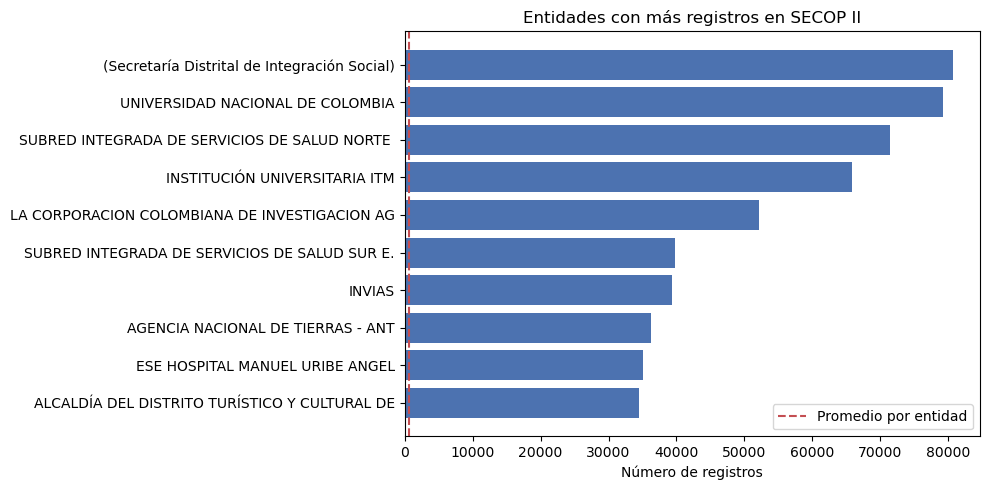

PythonRDD[1090] at RDD at PythonRDD.scala:53

In [56]:
# Gráfico de las 10 entidades con más registros

top10 = ranking[:10][::-1]
etiquetas = [(e or "(sin entidad)")[:45] for e, _ in top10]
valores = [v[0] for _, v in top10]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(etiquetas, valores, color="#4C72B0")
ax.axvline(promedio_por_entidad, color="#C44E52", linestyle="--", label="Promedio por entidad")
ax.set_xlabel("Número de registros")
ax.set_title("Entidades con más registros en SECOP II")
ax.legend()
plt.tight_layout()
plt.show()

sc.setLocalProperty("spark.job.description", None)
pares.unpersist()

### Conclusiones

**Tiempo y volumen de shuffle.**

Sobre 9.040.706 registros y 11.874 entidades, con 19 particiones en ambas alternativas:

| Alternativa | Mediana (s) | Shuffle escrito (MB) |
|---|---|---|
| `groupByKey` | 11,82 | 43,01 |
| `reduceByKey` | 4,39 | 4,95 |

`reduceByKey` fue 2,7 veces más rápido y movió 8,7 veces menos datos en el shuffle, con resultados idénticos para todas las entidades. La diferencia viene de la agregación local: con `groupByKey` se envían por el shuffle los 9 millones de valores y se agrupan en listas en el reductor, mientras que con `reduceByKey` cada partición envía como máximo un `(conteo, suma)` por entidad, es decir, a lo sumo 19 × 11.874 = 225.606 resultados parciales.

La mejora en tiempo (2,7×) es menor que la reducción de datos (8,7×) porque el shuffle no es el único costo: ambas alternativas recorren los mismos 9 millones de registros en caché y los serializan entre la JVM y Python. Además, en modo local el shuffle se escribe en el disco de la misma máquina; en un clúster, donde los datos sí cruzan la red, se esperaría una ventaja mayor para `reduceByKey`.

**Sesgo de datos (*data skew*).** La entidad que concentra más registros es la Secretaría Distrital de Integración Social, con 111.914 (1,24 % del total), seguida muy de cerca por la Universidad Nacional de Colombia, con 110.822. La distribución está muy sesgada: el promedio es de 761 registros por entidad, pero la mediana es de solo 72. La entidad mayor tiene 147 veces el promedio, y apenas el 2,47 % de las entidades (293) concentra la mitad de los registros.

A nivel de particiones el efecto es moderado: la más cargada recibe 646.888 registros, 1,4 veces el promedio (475.827), porque cada partición agrupa cientos de entidades y el peso de las grandes se diluye. Aun así, esa tarea es la que determina cuándo termina la etapa. Con `groupByKey` el sesgo pesa además en memoria: los 111.914 valores de la entidad mayor deben reunirse en una sola lista dentro de un mismo proceso, mientras que con `reduceByKey` esa entidad llega como, a lo sumo, 19 resultados parciales.

En conclusion para agregaciones asociativas como conteos y sumas conviene usar `reduceByKey` (o `aggregateByKey` / `combineByKey`) en lugar de `groupByKey`, porque reduce el volumen del shuffle, el tiempo de ejecución y la presión de memoria frente a claves sesgadas. La API de DataFrames aplica esta agregación parcial de forma automática en `groupBy().agg()`. Si el sesgo fuera más extremo, técnicas como el *salting* de la clave permitirían repartir una entidad pesada entre varias particiones.
